In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import geopandas as gpd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Read the shapefile
df = gpd.read_file('/content/drive/MyDrive/Flood_Susceptibility/New_Inventory/flood_invent_400.shp')
df.head()

,grid_code,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall,geometry
0,0,21.0,7.210669,1000.0,0.567845,5.603608,1.0,4.0,5.040757,34.478920,0.333333,2.405406,0.272727,2458.048096,POINT (648293.817 1116408.852)
1,0,14.0,5.139694,1000.0,0.444897,10.679511,1.0,4.0,7.578450,-20.343735,-0.444444,-1.729730,0.211433,2446.077881,POINT (648401.005 1117212.764)
2,0,32.0,4.380487,1000.0,0.676938,5.948130,1.0,4.0,4.632522,1.221863,0.333333,2.324324,0.578451,2490.737305,POINT (649472.887 1114693.841)
3,0,29.0,3.945476,1000.0,0.793863,7.326543,3.0,4.0,6.156691,48.258034,0.111111,1.486486,0.776360,2553.509277,POINT (650330.393 1113193.206)
4,0,12.0,1.909152,1000.0,0.743280,7.876605,5.0,4.0,4.476785,-50.000000,-0.555556,-1.081081,0.511879,2492.831543,POINT (651080.711 1114318.682)


In [ ]:
#check that there is no no data values in the dataset
print(df.isnull().sum())

grid_code      0
Relief         0
Slope          0
Dis_River      0
Drai_Densi     0
TWI            0
LULC           0
Geomorphol     0
SPI            0
Conv_Index     0
Curvature      0
TPI            0
NDVI          26
Rainfall       0
geometry       0
dtype: int64


<Axes: xlabel='grid_code', ylabel='count'>

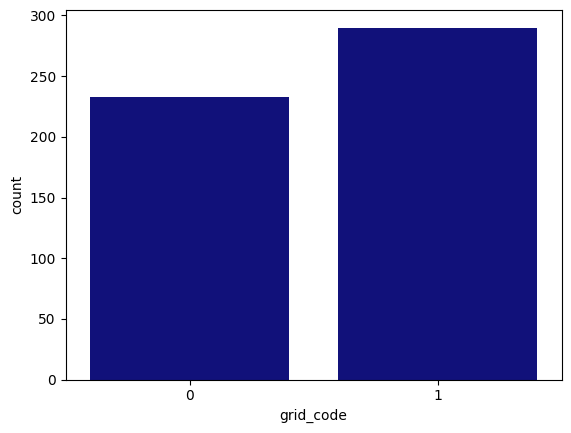

In [ ]:
# Understand the data
# Here we can see that we have a balanced dataset (equal number of flooded and non flooeded locations
sns.countplot(x="grid_code", data=df,color = 'darkblue') # 0 - Notflooded   B - Flooded

In [ ]:
# First, check the data types
print(df.dtypes)

# Select only numeric columns, excluding the target and geometry
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols.remove('grid_code')  # Remove target variable
X = df[numeric_cols]  # Features
y = df['grid_code']   # Target variable (flood/non-flood)

# Display the first few rows of the features
print(X.head())

grid_code        int64
Relief         float64
Slope          float64
Dis_River      float64
Drai_Densi     float64
TWI            float64
LULC           float64
Geomorphol     float64
SPI            float64
Conv_Index     float64
Curvature      float64
TPI            float64
NDVI           float64
Rainfall       float64
geometry      geometry
dtype: object
   Relief     Slope  Dis_River  Drai_Densi        TWI  LULC  Geomorphol  \
0    21.0  7.210669     1000.0    0.567845   5.603608   1.0         4.0   
1    14.0  5.139694     1000.0    0.444897  10.679511   1.0         4.0   
2    32.0  4.380487     1000.0    0.676938   5.948130   1.0         4.0   
3    29.0  3.945476     1000.0    0.793863   7.326543   3.0         4.0   
4    12.0  1.909152     1000.0    0.743280   7.876605   5.0         4.0   

        SPI  Conv_Index  Curvature       TPI      NDVI     Rainfall  
0  5.040757   34.478920   0.333333  2.405406  0.272727  2458.048096  
1  7.578450  -20.343735  -0.444444 -1.729730  0.21

In [ ]:
import pandas as pd
import numpy as np

# Define the valid ranges for each feature based on the images provided
valid_ranges = {
    'Relief': (3, 717),
    'Slope': (0, 58.9553),
    'Dis_River': (100, 1000),
    'Drai_Density': (0.0025849712, 4.8236695),
    'TWI': (3.3658473491669, 30.28600692749),
    'LULC': (1, 7),
    'Geomorphology': (1, 18),
    'SPI': (1.6694390773773, 15.068050384521),
    'Conv_Index': (-100, 100),
    'Curvature': (-10.111110687256, 7.4444446563721),
    'TPI': (-38.324325561523, 35.216217041016),
    'NDVI': (-0.4285714328289, 0.89060252904892),
    'Rainfall': (1849.0091552734, 3915.3872070312)  # Based on the new image provided
}

# Create a mask to identify points with values within valid ranges
mask = pd.Series(True, index=X.index)

# Check each column against its valid range
for column, (min_val, max_val) in valid_ranges.items():
    if column in X.columns:
        # Create a column-specific mask that's True for values within the valid range
        # Also consider NaN values as invalid
        column_mask = (
            (X[column] >= min_val) &
            (X[column] <= max_val) &
            (~X[column].isna()) &
            # Filter out extreme floating point values that might represent NoData
            (~np.isinf(X[column])) &
            (X[column] != -3.402823e+38) &
            (X[column] != 3.400000e+38) &
            (X[column] != -99999.0)
        )

        # Update the overall mask by performing an AND operation
        mask = mask & column_mask

# Apply the mask to filter the points
X_new = X[mask].copy()

# Check how many points were filtered out
print(f"Original number of points: {len(X)}")
print(f"Number of points after filtering: {len(X_new)}")
print(f"Number of points removed: {len(X) - len(X_new)}")

# Check the filtered GeoDataFrame
X_new.head()

# Optional: Save the filtered points to a new shapefile
# filtered_points.to_file("filtered_points.shp")

Original number of points: 523
Number of points after filtering: 472
Number of points removed: 51


,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall
0,21.0,7.210669,1000.0,0.567845,5.603608,1.0,4.0,5.040757,34.478920,0.333333,2.405406,0.272727,2458.048096
1,14.0,5.139694,1000.0,0.444897,10.679511,1.0,4.0,7.578450,-20.343735,-0.444444,-1.729730,0.211433,2446.077881
2,32.0,4.380487,1000.0,0.676938,5.948130,1.0,4.0,4.632522,1.221863,0.333333,2.324324,0.578451,2490.737305
3,29.0,3.945476,1000.0,0.793863,7.326543,3.0,4.0,6.156691,48.258034,0.111111,1.486486,0.776360,2553.509277
4,12.0,1.909152,1000.0,0.743280,7.876605,5.0,4.0,4.476785,-50.000000,-0.555556,-1.081081,0.511879,2492.831543


In [ ]:
X_new.describe()

,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall
count,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000
mean,27.838983,3.804470,790.042373,0.895363,11.273059,2.652542,4.593220,5.830895,-6.519688,-0.058851,-0.440189,0.632650,2353.180281
std,70.225535,4.397070,336.407899,0.373873,4.776191,1.254306,1.772579,2.200805,38.326686,0.605982,2.348570,0.168057,206.762006
min,4.000000,0.337615,100.000000,0.026172,4.843778,1.000000,1.000000,1.669439,-100.000000,-2.777778,-14.216216,0.049683,1892.483521
25%,8.000000,1.391763,500.000000,0.693667,6.956178,1.000000,4.000000,4.249762,-33.333332,-0.444444,-1.675676,0.551238,2249.541504
50%,11.000000,2.456395,1000.000000,0.922096,10.327789,3.000000,5.000000,5.488164,-6.827759,-0.111111,-0.513514,0.690672,2342.671875
75%,19.000000,4.545115,1000.000000,1.103280,14.765829,3.000000,5.000000,7.072701,18.672164,0.222222,0.925676,0.757589,2453.986633
max,707.000000,37.568253,1000.000000,2.634890,26.719210,5.000000,15.000000,13.379759,100.000000,2.444444,14.378378,0.857427,3656.540527


In [ ]:
# Checking NaN status again
print(X_new.isnull().sum())

Relief        0
Slope         0
Dis_River     0
Drai_Densi    0
TWI           0
LULC          0
Geomorphol    0
SPI           0
Conv_Index    0
Curvature     0
TPI           0
NDVI          0
Rainfall      0
dtype: int64


**Correlation Analysis**

In [ ]:
# Drop TPI
# X_new = X_new.drop(['TPI'], axis=1)

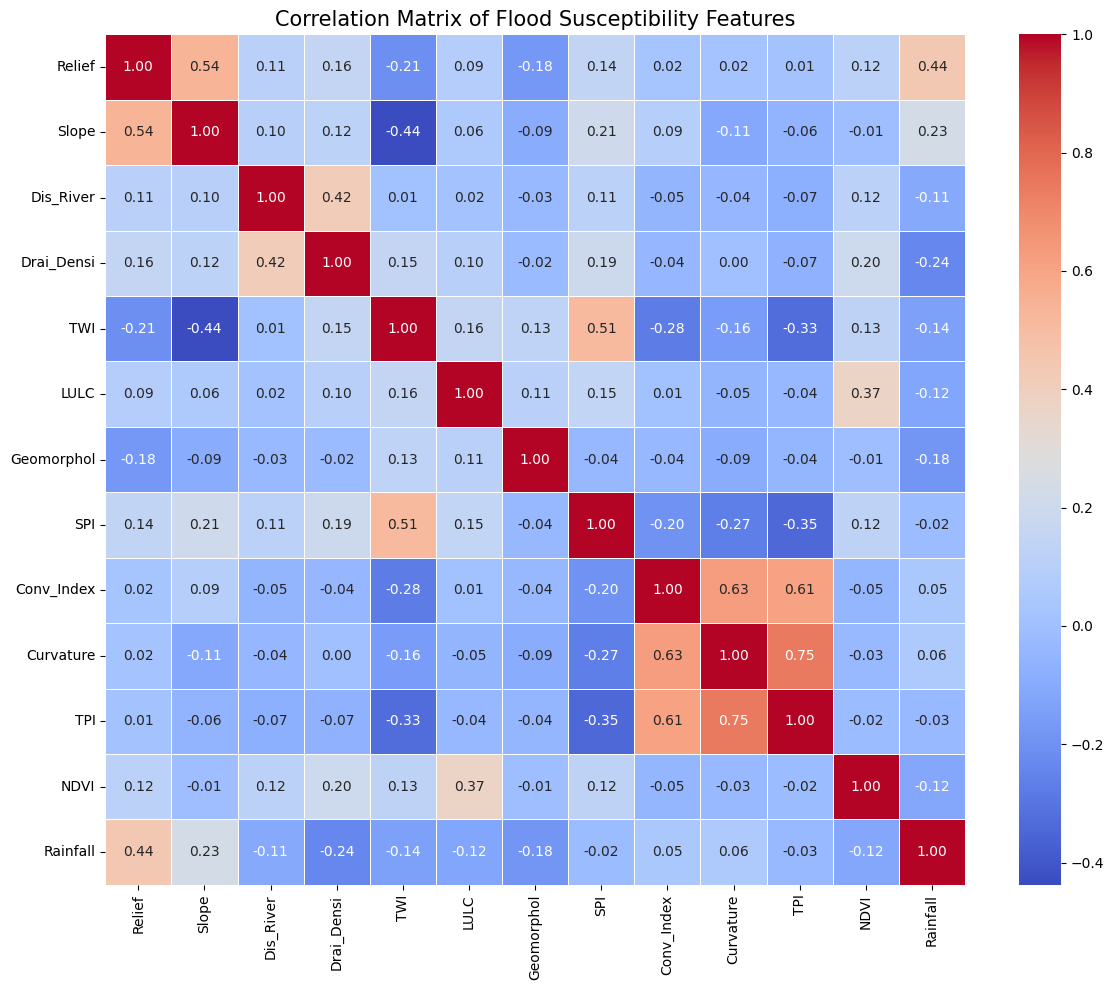

Highly correlated feature pairs (|r| > 0.7):
TPI and Curvature: 0.746


In [ ]:
# Calculate correlation matrix
correlation_matrix = X_new.corr()

# Create a heatmap visualization
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Flood Susceptibility Features', fontsize=15)
plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()

# Find highly correlated feature pairs (above a threshold)
threshold = 0.7  # You can adjust this threshold
high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            high_corr_pairs.append(
                (correlation_matrix.columns[i],
                 correlation_matrix.columns[j],
                 correlation_matrix.iloc[i, j])
            )

# Display high correlation pairs
if high_corr_pairs:
    print("Highly correlated feature pairs (|r| > {}):".format(threshold))
    for feat1, feat2, corr in high_corr_pairs:
        print(f"{feat1} and {feat2}: {corr:.3f}")
else:
    print(f"No feature pairs with correlation above {threshold} were found.")